In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Project location
project_folder = Path(
    r"C:\DataAnalytics\Marketplace-Intelligence"
)

# Database location
database_path = (
    project_folder / "data" / "processed" / "marketplace.db"
)

print("Libraries imported successfully!")
print("Database path:", database_path)

Libraries imported successfully!
Database path: C:\DataAnalytics\Marketplace-Intelligence\data\processed\marketplace.db


In [2]:
# Locate the saved cohort SQL query
sql_file = (
    project_folder
    / "sql"
    / "11_customer_cohort_retention.sql"
)

# Read the SQL query
query = sql_file.read_text(encoding="utf-8")

# Execute SQL and load results
with sqlite3.connect(database_path) as connection:
    cohort_data = pd.read_sql_query(query, connection)

print("Cohort data loaded successfully!")
print("Total rows:", len(cohort_data))

display(cohort_data.head(10))

Cohort data loaded successfully!
Total rows: 219


,cohort_month,month_number,cohort_size,active_customers,retention_percentage
0,2016-09,0,1,1,100.00
1,2016-10,0,262,262,100.00
2,2016-10,6,262,1,0.38
3,2016-10,9,262,1,0.38
4,2016-10,11,262,1,0.38
5,2016-10,13,262,1,0.38
6,2016-10,15,262,1,0.38
7,2016-10,17,262,1,0.38
8,2016-10,19,262,2,0.76
9,2016-10,20,262,2,0.76


In [3]:
# Convert cohort results into a matrix

retention_matrix = cohort_data.pivot(
    index="cohort_month",
    columns="month_number",
    values="retention_percentage"
)

# Sort cohorts from oldest to newest
retention_matrix = retention_matrix.sort_index()

# Display first 12 cohort months
display(retention_matrix.head(12))

month_number,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19,20
cohort_month,,,,,,,,,,,,,,,,,,,,
2016-09,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-10,100.0,NaN,NaN,NaN,NaN,NaN,0.38,NaN,NaN,0.38,NaN,0.38,NaN,0.38,NaN,0.38,NaN,0.38,0.76,0.76
2016-12,100.0,100.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01,100.0,0.28,0.28,0.14,0.42,0.14,0.42,0.14,0.14,NaN,0.42,0.14,0.70,0.42,0.14,0.14,0.28,0.42,0.14,NaN
2017-02,100.0,0.18,0.31,0.12,0.43,0.12,0.25,0.18,0.12,0.18,0.12,0.31,0.12,0.18,0.12,0.06,0.06,0.18,NaN,NaN
2017-03,100.0,0.44,0.36,0.40,0.36,0.16,0.16,0.32,0.32,0.08,0.36,0.12,0.20,0.12,0.16,0.24,0.08,0.12,NaN,NaN
2017-04,100.0,0.62,0.22,0.18,0.27,0.27,0.35,0.31,0.31,0.18,0.27,0.09,0.04,0.04,0.09,0.09,0.13,NaN,NaN,NaN
2017-05,100.0,0.46,0.46,0.29,0.29,0.32,0.41,0.14,0.26,0.26,0.26,0.35,0.23,0.03,0.17,0.20,NaN,NaN,NaN,NaN
2017-06,100.0,0.49,0.40,0.43,0.30,0.40,0.36,0.23,0.13,0.20,0.30,0.36,0.16,0.16,0.23,NaN,NaN,NaN,NaN,NaN


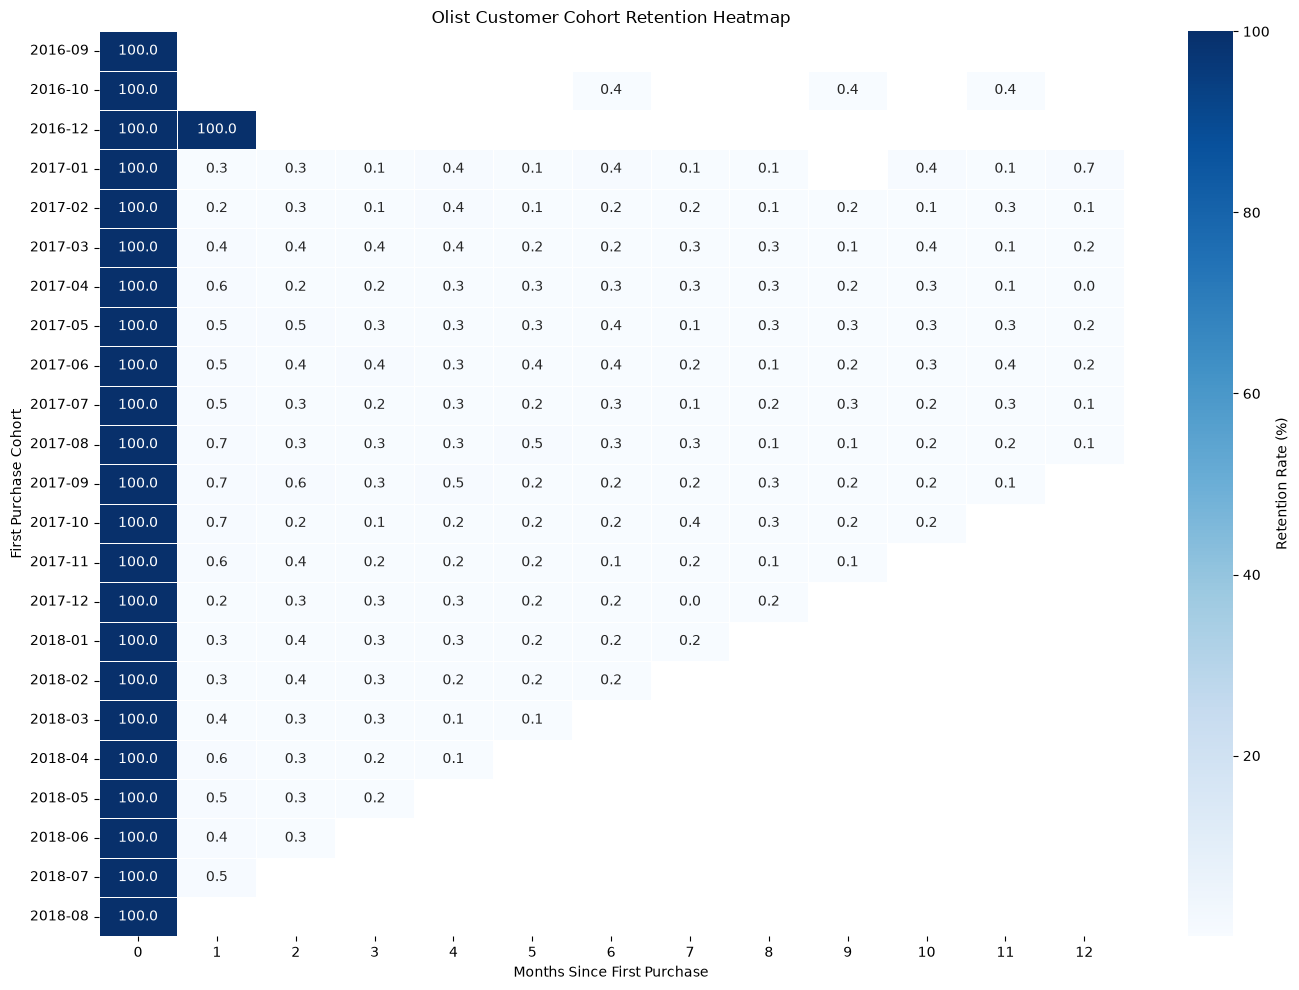

In [4]:
# Create the first cohort retention heatmap

import matplotlib.pyplot as plt
import seaborn as sns

# Select months 0 to 12
heatmap_data = retention_matrix.loc[:, 0:12]

plt.figure(figsize=(14, 10))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    mask=heatmap_data.isna(),
    linewidths=0.5,
    cbar_kws={"label": "Retention Rate (%)"}
)

plt.title("Olist Customer Cohort Retention Heatmap")
plt.xlabel("Months Since First Purchase")
plt.ylabel("First Purchase Cohort")

plt.tight_layout()
plt.show()

In [5]:
import pandas as pd
import numpy as np

# Use August 2018 as our reporting cutoff
last_observed_month = pd.Period("2018-08", freq="M")

# Create a complete matrix for months 0 to 12
retention_clean = retention_matrix.reindex(
    columns=range(13)
).copy()

# Replace missing values only for observable months
for cohort in retention_clean.index:

    cohort_period = pd.Period(cohort, freq="M")

    for month_number in retention_clean.columns:

        activity_month = cohort_period + month_number

        if activity_month <= last_observed_month:
            if pd.isna(retention_clean.loc[cohort, month_number]):
                retention_clean.loc[cohort, month_number] = 0.0

        else:
            retention_clean.loc[cohort, month_number] = np.nan

print("Retention matrix prepared successfully!")

display(retention_clean.head(10))

Retention matrix prepared successfully!


month_number,0,1,2,3,4,5,6,7,8,9,10,11,12
cohort_month,,,,,,,,,,,,,
2016-09,100.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2016-10,100.0,0.00,0.00,0.00,0.00,0.00,0.38,0.00,0.00,0.38,0.00,0.38,0.00
2016-12,100.0,100.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2017-01,100.0,0.28,0.28,0.14,0.42,0.14,0.42,0.14,0.14,0.00,0.42,0.14,0.70
2017-02,100.0,0.18,0.31,0.12,0.43,0.12,0.25,0.18,0.12,0.18,0.12,0.31,0.12
2017-03,100.0,0.44,0.36,0.40,0.36,0.16,0.16,0.32,0.32,0.08,0.36,0.12,0.20
2017-04,100.0,0.62,0.22,0.18,0.27,0.27,0.35,0.31,0.31,0.18,0.27,0.09,0.04
2017-05,100.0,0.46,0.46,0.29,0.29,0.32,0.41,0.14,0.26,0.26,0.26,0.35,0.23
2017-06,100.0,0.49,0.40,0.43,0.30,0.40,0.36,0.23,0.13,0.20,0.30,0.36,0.16


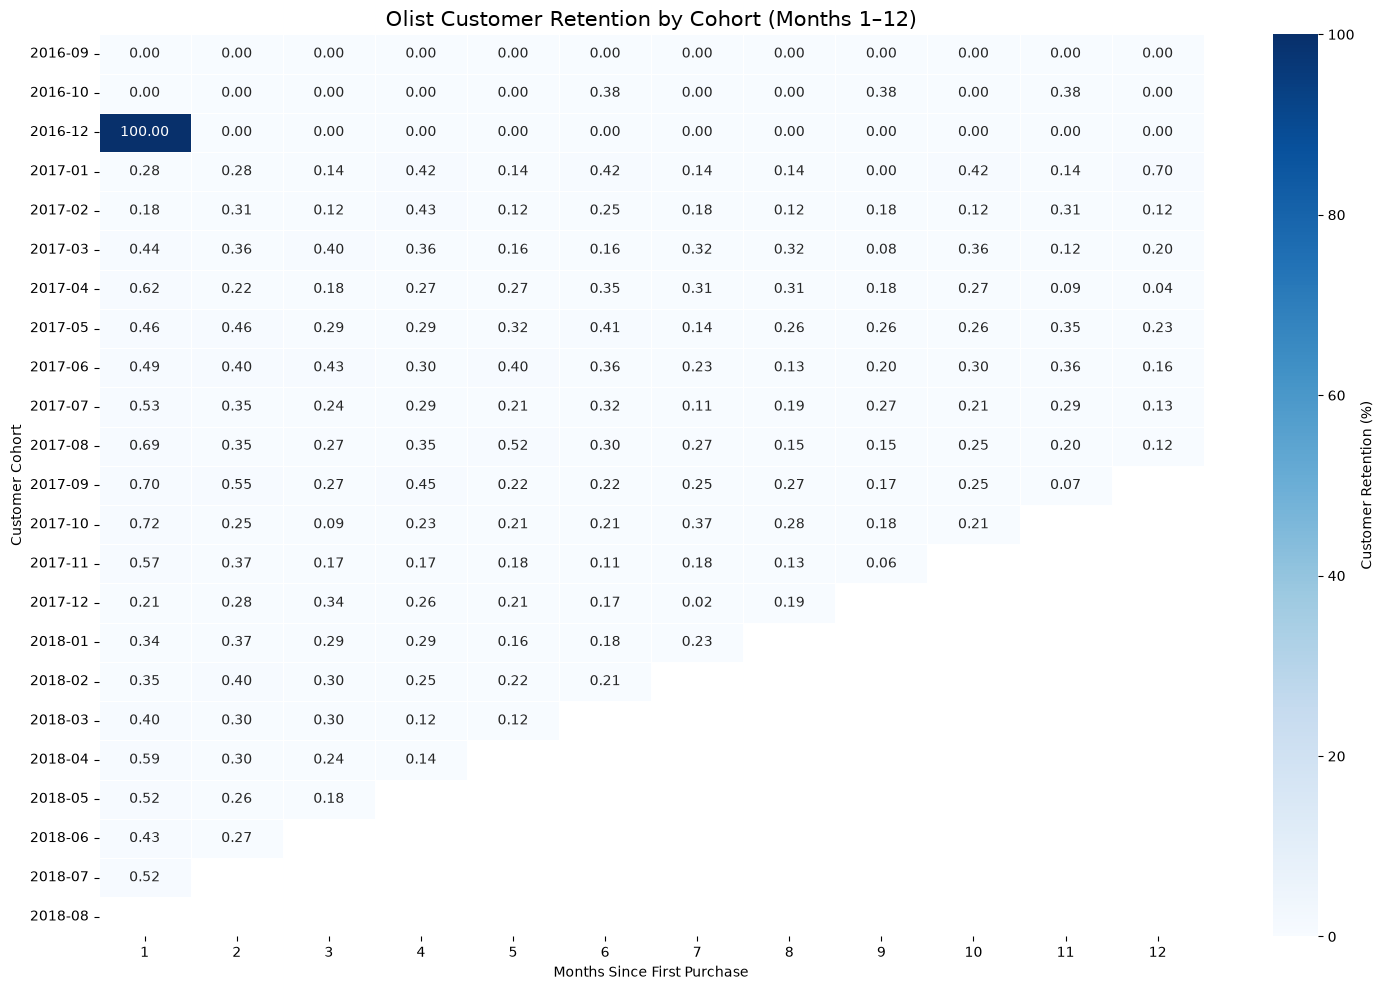

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Show months 1 to 12 only
heatmap_improved = retention_clean.loc[:, 1:12]

plt.figure(figsize=(15, 10))

sns.heatmap(
    heatmap_improved,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    mask=heatmap_improved.isna(),
    linewidths=0.5,
    cbar_kws={"label": "Customer Retention (%)"}
)

plt.title(
    "Olist Customer Retention by Cohort (Months 1–12)",
    fontsize=15
)

plt.xlabel("Months Since First Purchase")
plt.ylabel("Customer Cohort")

plt.tight_layout()
plt.show()

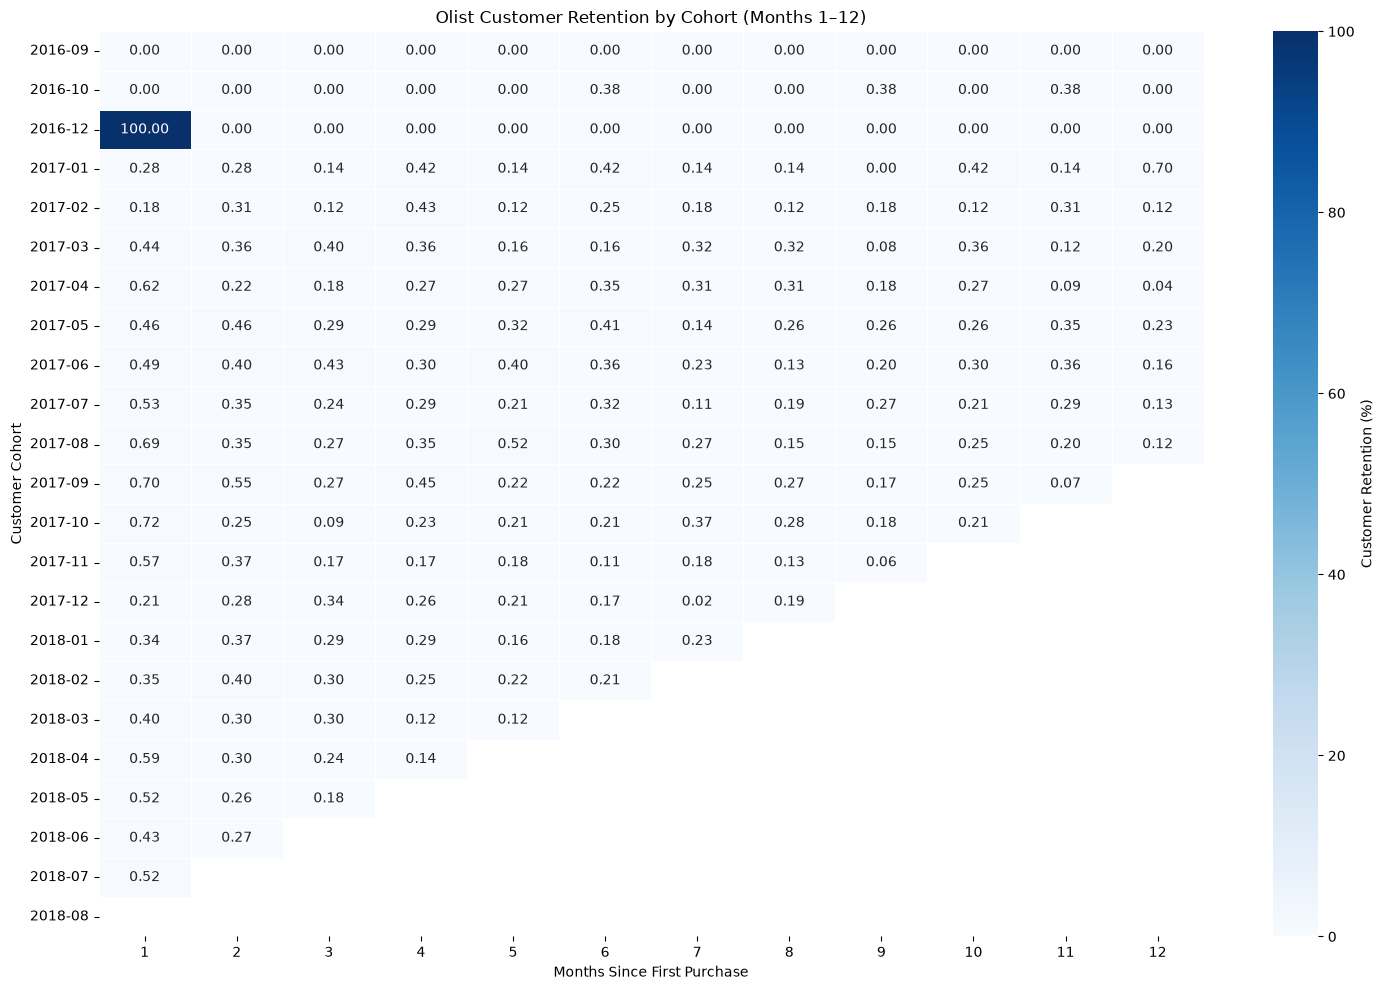

Heatmap saved successfully!


In [7]:
# Save the improved heatmap

output_folder = project_folder / "reports"

output_folder.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(15, 10))

sns.heatmap(
    heatmap_improved,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    mask=heatmap_improved.isna(),
    linewidths=0.5,
    cbar_kws={"label": "Customer Retention (%)"}
)

plt.title("Olist Customer Retention by Cohort (Months 1–12)")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Customer Cohort")

plt.tight_layout()

plt.savefig(
    output_folder / "customer_retention_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Heatmap saved successfully!")

In [8]:
# Calculate weighted customer retention KPIs

import pandas as pd

last_observed_month = pd.Period("2018-08", freq="M")

retention_results = []

for month_number in [1, 3, 6]:

    # Select cohorts with enough follow-up time
    eligible = cohort_data[
        cohort_data["cohort_month"].apply(
            lambda x: (
                pd.Period(x, freq="M") + month_number
                <= last_observed_month
            )
        )
    ]

    # Get all eligible cohort sizes from Month 0
    cohort_sizes = cohort_data[
        (cohort_data["month_number"] == 0)
        & (
            cohort_data["cohort_month"].apply(
                lambda x: (
                    pd.Period(x, freq="M") + month_number
                    <= last_observed_month
                )
            )
        )
    ]

    # Count returning customers at the selected month
    returning = eligible[
        eligible["month_number"] == month_number
    ]["active_customers"].sum()

    total_customers = cohort_sizes["cohort_size"].sum()

    retention_rate = (
        returning / total_customers * 100
        if total_customers > 0 else float("nan")
    )

    retention_results.append({
        "Month": month_number,
        "Eligible_Customers": total_customers,
        "Returning_Customers": returning,
        "Retention_Rate": round(retention_rate, 2)
    })

retention_kpis = pd.DataFrame(retention_results)

display(retention_kpis)

,Month,Eligible_Customers,Returning_Customers,Retention_Rate
0,1,87214,421,0.48
1,3,75387,192,0.25
2,6,55525,129,0.23


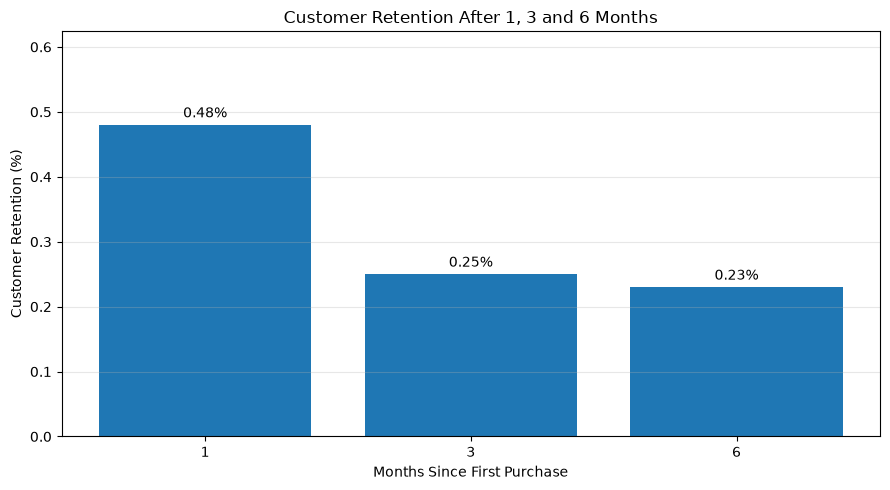

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

bars = plt.bar(
    retention_kpis["Month"].astype(str),
    retention_kpis["Retention_Rate"]
)

plt.bar_label(bars, fmt="%.2f%%", padding=3)

plt.title("Customer Retention After 1, 3 and 6 Months")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Customer Retention (%)")

plt.ylim(
    0,
    max(retention_kpis["Retention_Rate"].max() * 1.3, 0.1)
)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
# Save retention KPIs for the business report

output_folder = project_folder / "reports"

output_folder.mkdir(parents=True, exist_ok=True)

retention_kpis.to_csv(
    output_folder / "customer_retention_kpis.csv",
    index=False
)

print("Customer retention KPI results saved successfully!")

Customer retention KPI results saved successfully!


In [11]:
# Analyse Month 1 customer retention by cohort

month1_retention = cohort_data[
    (cohort_data["month_number"] == 1) &
    (cohort_data["cohort_month"] >= "2017-01") &
    (cohort_data["cohort_month"] <= "2018-07")
][
    [
        "cohort_month",
        "cohort_size",
        "active_customers",
        "retention_percentage"
    ]
].copy()

# Add observable cohorts with zero returning customers
eligible_cohorts = cohort_data[
    (cohort_data["month_number"] == 0) &
    (cohort_data["cohort_month"] >= "2017-01") &
    (cohort_data["cohort_month"] <= "2018-07")
][["cohort_month", "cohort_size"]].drop_duplicates()

month1_retention = eligible_cohorts.merge(
    month1_retention.drop(columns="cohort_size"),
    on="cohort_month",
    how="left",
    validate="one_to_one"
)

month1_retention["active_customers"] = (
    month1_retention["active_customers"].fillna(0).astype(int)
)

month1_retention["retention_percentage"] = (
    month1_retention["active_customers"]
    / month1_retention["cohort_size"] * 100
).round(2)

print("TOP 5 MONTH 1 RETENTION COHORTS")

display(
    month1_retention.sort_values(
        "retention_percentage",
        ascending=False
    ).head(5)
)

print("BOTTOM 5 MONTH 1 RETENTION COHORTS")

display(
    month1_retention.sort_values(
        "retention_percentage"
    ).head(5)
)

TOP 5 MONTH 1 RETENTION COHORTS


,cohort_month,cohort_size,active_customers,retention_percentage
9,2017-10,4328,31,0.72
8,2017-09,4004,28,0.70
7,2017-08,4057,28,0.69
3,2017-04,2256,14,0.62
15,2018-04,6582,39,0.59


BOTTOM 5 MONTH 1 RETENTION COHORTS


,cohort_month,cohort_size,active_customers,retention_percentage
1,2017-02,1628,3,0.18
11,2017-12,5338,11,0.21
0,2017-01,717,2,0.28
12,2018-01,6842,23,0.34
13,2018-02,6288,22,0.35


In [12]:
# Calculate average delivered orders per customer

query = """
WITH customer_orders AS (
    SELECT
        c.customer_unique_id,
        COUNT(DISTINCT o.order_id) AS total_orders
    FROM orders AS o
    INNER JOIN customers AS c
        ON o.customer_id = c.customer_id
    WHERE o.order_status = 'delivered'
    GROUP BY c.customer_unique_id
)

SELECT
    COUNT(*) AS total_customers,
    SUM(total_orders) AS total_delivered_orders,
    ROUND(AVG(total_orders), 4)
        AS average_orders_per_customer
FROM customer_orders;
"""

with sqlite3.connect(database_path) as connection:
    purchase_summary = pd.read_sql_query(query, connection)

display(purchase_summary)

,total_customers,total_delivered_orders,average_orders_per_customer
0,93358,96478,1.0334


### Business Findings: Customer Retention and Repeat Purchasing

**Business Problem**

The marketplace needs to understand whether customers return for additional purchases and how repeat purchasing differs between customer groups.

**Analytical Methods**

- SQL JOINs and Common Table Expressions (CTEs)
- Customer identification using `customer_unique_id`
- Purchase-frequency analysis
- Monthly cohort retention analysis
- Weighted customer retention KPIs
- Retention heatmap visualization

**Key Findings**

1. The historical dataset contains 93,358 customers with at least one delivered order.
2. Of these customers, 90,557 made only one delivered purchase.
3. A total of 2,801 customers made more than one delivered purchase.
4. The observed repeat-customer percentage is approximately 3%.
5. Monthly cohort retention rates are generally low in the observed historical period.

**Business Interpretation**

The marketplace shows limited observed repeat purchasing. This may indicate an opportunity to investigate customer engagement and purchasing behaviour, but the data alone cannot establish why customers do not return.

**Potential Recommendations**

- Investigate the experience of first-time customers.
- Analyse repeat purchasing by product category and customer location.
- Consider testing targeted second-purchase incentives.
- Measure the effectiveness of retention campaigns using controlled experiments.

**Limitations**

- The dataset contains historical transactions rather than current marketplace activity.
- Customers have different amounts of available follow-up time.
- Monthly retention measures purchases in specific calendar months, not cumulative repeat-purchase rates.
- Recommendations are hypotheses that require further analysis and testing.